In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the raw symptom dataset without assuming a header row
df_raw = pd.read_csv('Data/dataset.csv', header=None)
df_raw = df_raw.dropna(how='all').reset_index(drop=True)
df_raw.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# Set clean column headers
cols = ['Disease'] + [f'Symptom_{i}' for i in range(1, 18)]
df_raw.columns = cols[:df_raw.shape[1]]

# Display first 5 rows with proper headers
df_raw.head()


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# 1. DATA CLEANING: remove records where the disease target is missing
df_raw = df_raw.dropna(subset=['Disease']).copy()

# 2. DATA TRANSFORMATION: load the supplied one-hot encoded datasets
df_train = pd.read_csv('Data/Training.csv')
df_test = pd.read_csv('Data/Testing.csv')
print('DataSet Information: ')
df_raw.info()
print('Missing values in target:', df_raw['Disease'].isnull().sum())
print('Raw dataset shape:', df_raw.shape)
print('Training dataset shape:', df_train.shape)
print('Testing dataset shape:', df_test.shape)
print('Duplicate training rows:', df_train.duplicated().sum())
print('Duplicate testing rows:', df_test.duplicated().sum())

# The training data is already binary encoded: symptom columns contain 0 or 1.
df_train.head()

DataSet Information: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Disease     4920 non-null   object
 1   Symptom_1   4920 non-null   object
 2   Symptom_2   4920 non-null   object
 3   Symptom_3   4920 non-null   object
 4   Symptom_4   4572 non-null   object
 5   Symptom_5   3714 non-null   object
 6   Symptom_6   2934 non-null   object
 7   Symptom_7   2268 non-null   object
 8   Symptom_8   1944 non-null   object
 9   Symptom_9   1692 non-null   object
 10  Symptom_10  1512 non-null   object
 11  Symptom_11  1194 non-null   object
 12  Symptom_12  744 non-null    object
 13  Symptom_13  504 non-null    object
 14  Symptom_14  306 non-null    object
 15  Symptom_15  240 non-null    object
 16  Symptom_16  192 non-null    object
 17  Symptom_17  72 non-null     object
dtypes: object(18)
memory usage: 692.0+ KB
Missing values in target: 0


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


In [4]:
print(df_raw.isnull().sum().sum())  # Total missing values check
print(df_train.isnull().sum().sum())

46992
0


In [5]:
# ==========================================
# Handling Structural NaNs in Raw Dataset
# ==========================================

# Missing symptom entries mean that no additional symptom was recorded.
df_cleaned_raw = df_raw.fillna('None')

print("Null values after filling structural gaps:", df_cleaned_raw.isnull().sum().sum())
print("Duplicate raw records:", df_cleaned_raw.duplicated().sum())
df_cleaned_raw.head(3)

Null values after filling structural gaps: 0
Duplicate raw records: 4616


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None


In [6]:
# Display the cleaned raw dataframe to confirm NaNs are replaced
df_cleaned_raw.head(50)

,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
3,Fungal infection,itching,skin_rash,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,None,None,None,None,None,None,None,None,None,None,None,None,None,None
5,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
6,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
7,Fungal infection,itching,skin_rash,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
8,Fungal infection,itching,skin_rash,nodal_skin_eruptions,None,None,None,None,None,None,None,None,None,None,None,None,None,None
9,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None


In [7]:
# Basic Exploratory Inspection Commands for Viva Demonstration
print("--- 1. Dataset Shape (Rows & Columns) ---")
print(df_train.shape)

print("\n--- 2. Dataset Information & Data Types ---")
print(df_train.info())

print("\n--- 3. Checking for Missing Values Across All Columns ---")
print(df_train.isnull().sum().sum())  # Total missing values check

print("\n--- 4. First 3 Rows Preview ---")
display(df_train.head(3))

--- 1. Dataset Shape (Rows & Columns) ---
(4920, 133)

--- 2. Dataset Information & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Columns: 133 entries, itching to prognosis
dtypes: int64(132), object(1)
memory usage: 5.0+ MB
None

--- 3. Checking for Missing Values Across All Columns ---
0

--- 4. First 3 Rows Preview ---


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


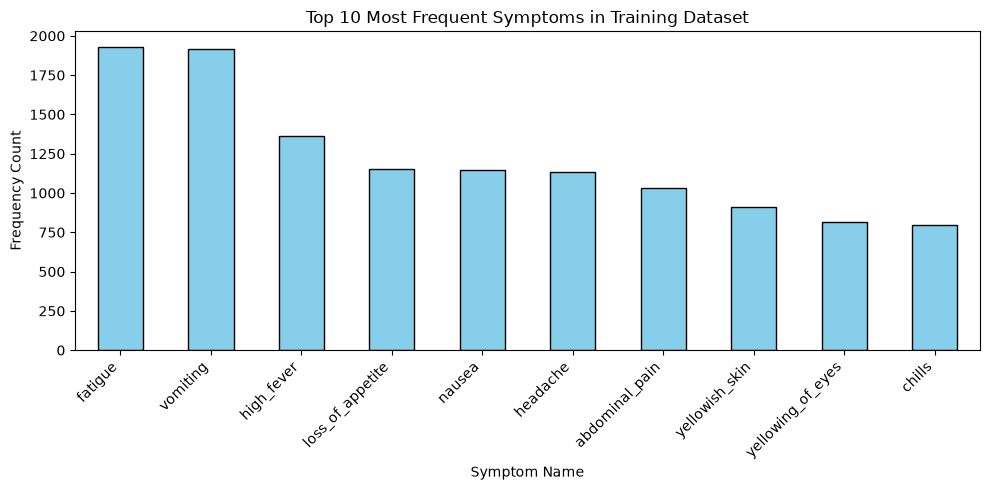

Observation: The most frequent symptoms occur across many disease records and may be useful baseline predictors.


In [8]:
# EXPLORATORY DATA ANALYSIS: Top 10 Most Frequent Symptoms
symptom_columns = df_train.drop(columns=['prognosis'])
symptom_counts = symptom_columns.sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
symptom_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Top 10 Most Frequent Symptoms in Training Dataset')
plt.xlabel('Symptom Name')
plt.ylabel('Frequency Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print('Observation: The most frequent symptoms occur across many disease records and may be useful baseline predictors.')

---
# NEW CELLS START HERE
*(Everything above is your original work. Delete your old cells 8 to 12 and use the cells below.)*

## 8. Why was the accuracy 100%? (Bug investigation)
The old model was tested on `Testing.csv`, but those rows already exist inside `Training.csv`. Let's prove it.

In [9]:
# How many rows are really different?
print('Total rows in Training.csv :', len(df_train))
print('Unique rows                :', len(df_train.drop_duplicates()))

# Are the Testing.csv rows really "new" data? Count how many are already inside Training.csv
same_rows = df_test.merge(df_train.drop_duplicates(), how='inner')
print('Testing rows already inside Training.csv:', len(same_rows), 'out of', len(df_test))

Total rows in Training.csv : 4920
Unique rows                : 304
Testing rows already inside Training.csv: 41 out of 41


Testing rows already inside Training.csv: 41 out of 41


**Result:** all 41 testing rows are already in the training data, and the 4,920 rows contain only 304 different ones. A model that simply memorises the training rows will therefore score 100%.

Next we show the same problem even if we split `Training.csv` ourselves **without** removing duplicates.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_all = df_train.drop(columns='prognosis')     # symptoms
y_all = df_train['prognosis']                  # disease

# Normal 80/20 split but duplicates are still there
Xa, Xb, ya, yb = train_test_split(X_all, y_all, test_size=0.2, random_state=42)

leaky_model = DecisionTreeClassifier(random_state=42)
leaky_model.fit(Xa, ya)

leaky_accuracy = leaky_model.score(Xb, yb)
print('Accuracy WITH duplicates         :', round(leaky_accuracy * 100, 1), '%')
print('Test rows also present in train  :', len(Xb.merge(Xa.drop_duplicates(), how='inner')), 'out of', len(Xb))

Accuracy WITH duplicates         : 100.0 %
Test rows also present in train  : 984 out of 984


## 9. Data Cleaning (the fix)
Three small problems are fixed here:
1. `fluid_overload` appears **twice** in `Training.csv`. The first copy is all zeros (useless), so there are really **131** symptoms, not 132.
2. Some column names have stray spaces, e.g. `dischromic _patches`.
3. Some disease names have extra spaces.

Then the most important step: **remove duplicate rows BEFORE splitting**.

In [11]:
# 1) Remove the empty duplicate column 'fluid_overload' and keep the real one ('fluid_overload.1')
if 'fluid_overload.1' in df_train.columns:
    print('Sum of the first fluid_overload column:', df_train['fluid_overload'].sum(), '(all zeros)')
    df_train = df_train.drop(columns='fluid_overload')
    df_train = df_train.rename(columns={'fluid_overload.1': 'fluid_overload'})

# 2) Remove spaces inside column names:  'dischromic _patches' -> 'dischromic_patches'
df_train.columns = df_train.columns.str.replace(' ', '')

# 3) Remove extra spaces from disease names
df_train['prognosis'] = df_train['prognosis'].str.replace(r'\s+', ' ', regex=True).str.strip()

print('Columns now:', df_train.shape[1], '(131 symptoms + 1 disease)')

Sum of the first fluid_overload column: 0 (all zeros)
Columns now: 132 (131 symptoms + 1 disease)


In [12]:
# 4) Remove duplicate rows
df_unique = df_train.drop_duplicates().reset_index(drop=True)

print('Rows before removing duplicates:', len(df_train))
print('Rows after removing duplicates :', len(df_unique))
print('Number of symptoms (features)  :', df_unique.shape[1] - 1)
print('Number of diseases             :', df_unique['prognosis'].nunique())

Rows before removing duplicates: 4920
Rows after removing duplicates : 304
Number of symptoms (features)  : 131
Number of diseases             : 41


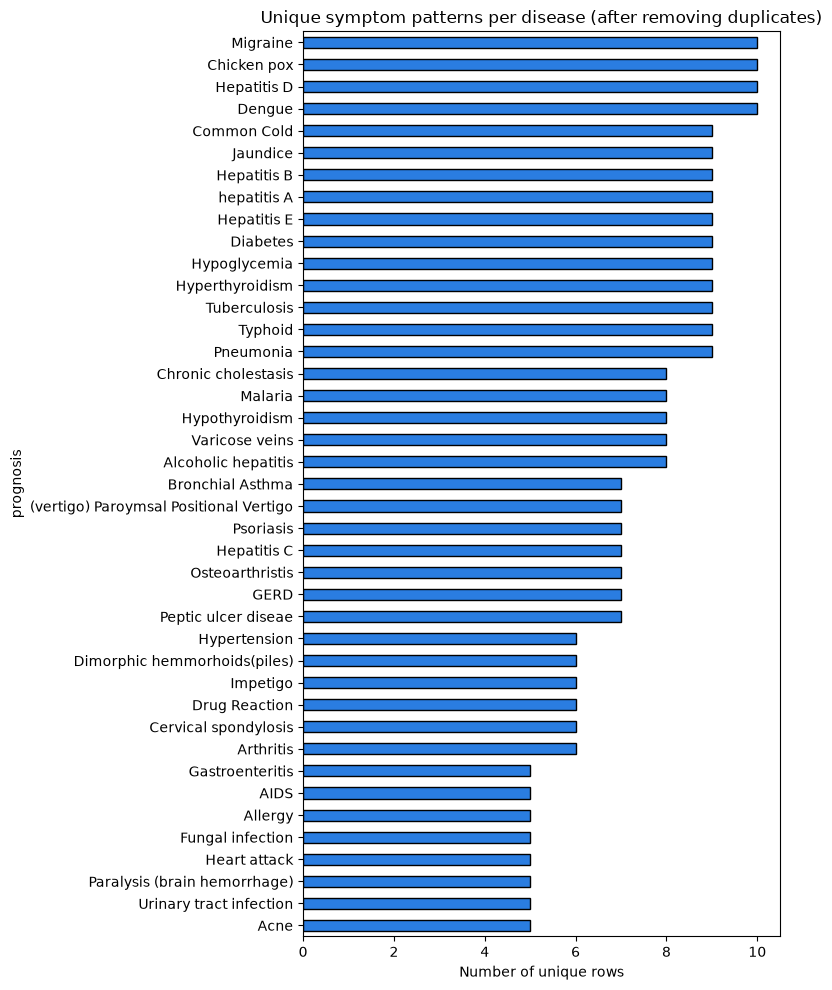

Observation: every disease has only 5 to 10 different patterns. The old "120 per disease" was just copies.


In [13]:
# How many unique symptom patterns does each disease really have?
pattern_counts = df_unique['prognosis'].value_counts().sort_values()

plt.figure(figsize=(8, 10))
pattern_counts.plot(kind='barh', color='#2a7de1', edgecolor='black')
plt.title('Unique symptom patterns per disease (after removing duplicates)')
plt.xlabel('Number of unique rows')
plt.tight_layout()
plt.show()

print('Observation: every disease has only 5 to 10 different patterns. The old "120 per disease" was just copies.')

## 10. Train / Test Split
The data is now de-duplicated, so a test row can never be a copy of a training row.
`stratify=y` makes sure every disease appears in both parts.

In [14]:
feature_columns = [c for c in df_unique.columns if c != 'prognosis']

X = df_unique[feature_columns]      # input: 131 symptoms (0 or 1)
y = df_unique['prognosis']          # output: disease name

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Training rows:', len(X_train))
print('Testing rows :', len(X_test))

# Safety check: are there any rows that are in BOTH train and test?
both = X_test.merge(X_train, how='inner')
print('Rows present in both train and test:', len(both), ' (must be 0)')

Training rows: 243
Testing rows : 61
Rows present in both train and test: 0  (must be 0)


## 11. Train and Compare Models
We train six algorithms from the syllabus and compare them on the **same** train/test split.

| Model | Simple idea |
|---|---|
| Logistic Regression | draws a straight-line boundary between diseases |
| KNN | looks at the 5 most similar patients |
| Decision Tree | a flowchart of yes/no symptom questions |
| Random Forest | many decision trees voting together |
| Naive Bayes | uses probabilities of each symptom for each disease |
| SVM | finds the widest-margin boundary between diseases |

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings('ignore')    # hide harmless version warnings
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'KNN':                 KNeighborsClassifier(n_neighbors=5),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42),
    'Naive Bayes':         BernoulliNB(),
    'SVM':                 SVC(kernel='linear', probability=True, random_state=42),
}

table = []
for name, model in models.items():
    model.fit(X_train, y_train)                 # learn from training data
    pred = model.predict(X_test)                # predict on unseen test data
    table.append({
        'Model': name,
        'Train Accuracy': model.score(X_train, y_train),
        'Test Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, pred, average='macro', zero_division=0),
        'F1 Score': f1_score(y_test, pred, average='macro', zero_division=0),
    })

results = pd.DataFrame(table).set_index('Model')
results.round(3)

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
Model,,,,,
Logistic Regression,1.000,1.000,1.000,1.000,1.000
KNN,1.000,1.000,1.000,1.000,1.000
Decision Tree,1.000,0.689,0.613,0.634,0.589
Random Forest,1.000,1.000,1.000,1.000,1.000
Naive Bayes,0.988,0.967,0.955,0.963,0.954
SVM,1.000,1.000,1.000,1.000,1.000


### Cross-Validation (5-fold)
The test set is small (only 61 rows), so one split can be lucky or unlucky. Cross-validation splits the data into 5 parts and tests on each part in turn.

In [16]:
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings('ignore')    # hide harmless version warnings
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5)      # 5 accuracy scores
    cv_results[name] = scores.mean()                 # average of the 5

results['CV Accuracy'] = pd.Series(cv_results)
results['Overfit Gap'] = results['Train Accuracy'] - results['Test Accuracy']
results.round(3)

,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,CV Accuracy,Overfit Gap
Model,,,,,,,
Logistic Regression,1.000,1.000,1.000,1.000,1.000,1.000,0.000
KNN,1.000,1.000,1.000,1.000,1.000,1.000,0.000
Decision Tree,1.000,0.689,0.613,0.634,0.589,0.628,0.311
Random Forest,1.000,1.000,1.000,1.000,1.000,1.000,0.000
Naive Bayes,0.988,0.967,0.955,0.963,0.954,0.977,0.020
SVM,1.000,1.000,1.000,1.000,1.000,1.000,0.000


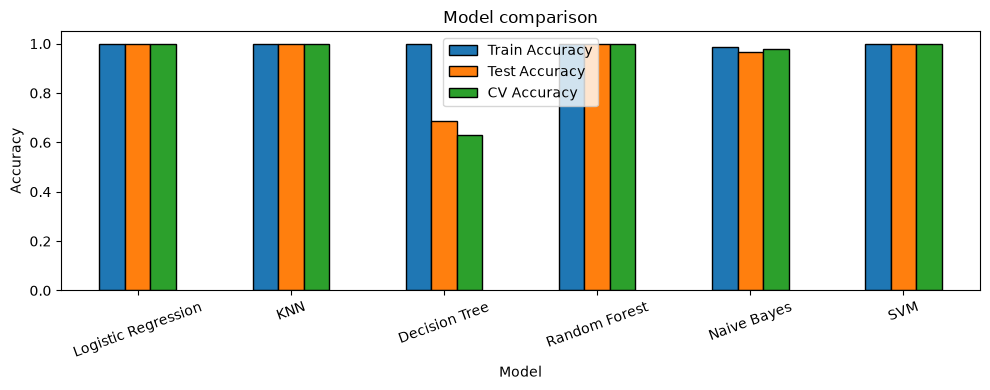

In [17]:
# Chart: train vs test vs cross-validation accuracy
results[['Train Accuracy', 'Test Accuracy', 'CV Accuracy']].plot(kind='bar', figsize=(10, 4), edgecolor='black')
plt.title('Model comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**How to explain this in the viva**
- The **Decision Tree** gets 100% on training data but much less on new data. This is **overfitting**: it memorised instead of learning. The old project hid this problem because its test data was the training data.
- The other models have almost no gap between train and test, so they generalise well.
- Several models reach 100% because this dataset is **synthetic and very clean** (each disease has a fixed symptom set). That is a property of the dataset, not a data leak any more.

In [18]:
# Before vs After
print('OLD project (duplicates in test)   :', round(leaky_accuracy * 100, 1), '%')
print('NEW Decision Tree (honest test)    :', round(results.loc['Decision Tree', 'Test Accuracy'] * 100, 1), '%')
print('NEW Decision Tree (cross-validated):', round(results.loc['Decision Tree', 'CV Accuracy'] * 100, 1), '%')

OLD project (duplicates in test)   : 100.0 %
NEW Decision Tree (honest test)    : 68.9 %
NEW Decision Tree (cross-validated): 62.8 %


## 12. Robustness Test (real patients don't report every symptom)
Here we hide some of each patient's symptoms at random and check which model still predicts correctly.
- `Drop 25%` = every symptom has a 25% chance of being hidden
- `Drop 50%` = every symptom has a 50% chance of being hidden

Each test is repeated 20 times and averaged.

In [19]:
np.random.seed(42)                     # same random numbers every run

robust = {}
for name, model in models.items():
    row = {'Clean': model.score(X_test, y_test)}

    for drop in [0.25, 0.50]:
        accs = []
        for i in range(20):
            keep = np.random.rand(X_test.shape[0], X_test.shape[1]) > drop   # True = keep symptom
            X_hidden = X_test * keep                                         # hidden symptoms become 0
            accs.append(model.score(X_hidden, y_test))
        row['Drop ' + str(int(drop * 100)) + '%'] = np.mean(accs)

    robust[name] = row

robust_df = pd.DataFrame(robust).T
robust_df['Average'] = robust_df.mean(axis=1)
robust_df.round(3)

,Clean,Drop 25%,Drop 50%,Average
Logistic Regression,1.000,0.972,0.823,0.932
KNN,1.000,0.949,0.661,0.870
Decision Tree,0.689,0.554,0.375,0.539
Random Forest,1.000,0.970,0.802,0.924
Naive Bayes,0.967,0.904,0.692,0.854
SVM,1.000,0.948,0.637,0.861


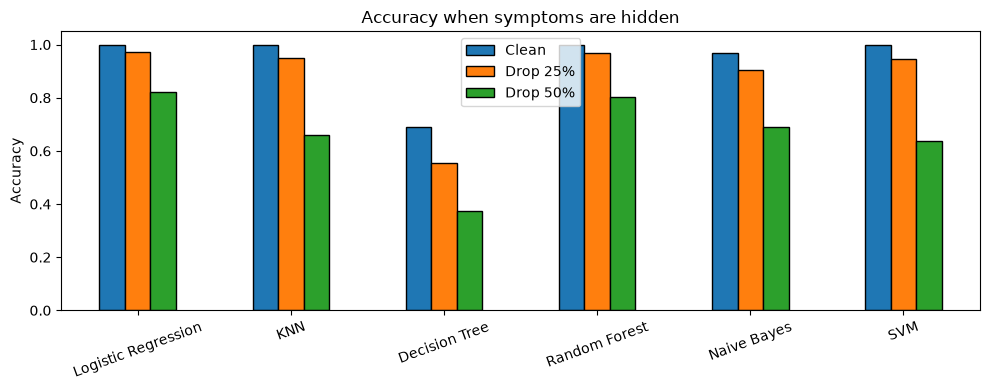

Selected final model: Logistic Regression


In [20]:
robust_df[['Clean', 'Drop 25%', 'Drop 50%']].plot(kind='bar', figsize=(10, 4), edgecolor='black')
plt.title('Accuracy when symptoms are hidden')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Pick the model with the best average robustness
best_name = robust_df['Average'].idxmax()
final_model = models[best_name]
print('Selected final model:', best_name)

## 13. Detailed Evaluation of the Final Model
`cross_val_predict` gives a prediction for **every** patient from a model that never saw that patient, which is more reliable than only 61 test rows.

In [21]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

cv_pred = cross_val_predict(final_model, X, y, cv=5)

print('Final model:', best_name)
print('Accuracy :', round(accuracy_score(y, cv_pred), 3))
print('Precision:', round(precision_score(y, cv_pred, average='macro', zero_division=0), 3))
print('Recall   :', round(recall_score(y, cv_pred, average='macro', zero_division=0), 3))
print('F1 Score :', round(f1_score(y, cv_pred, average='macro', zero_division=0), 3))

Final model: Logistic Regression
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


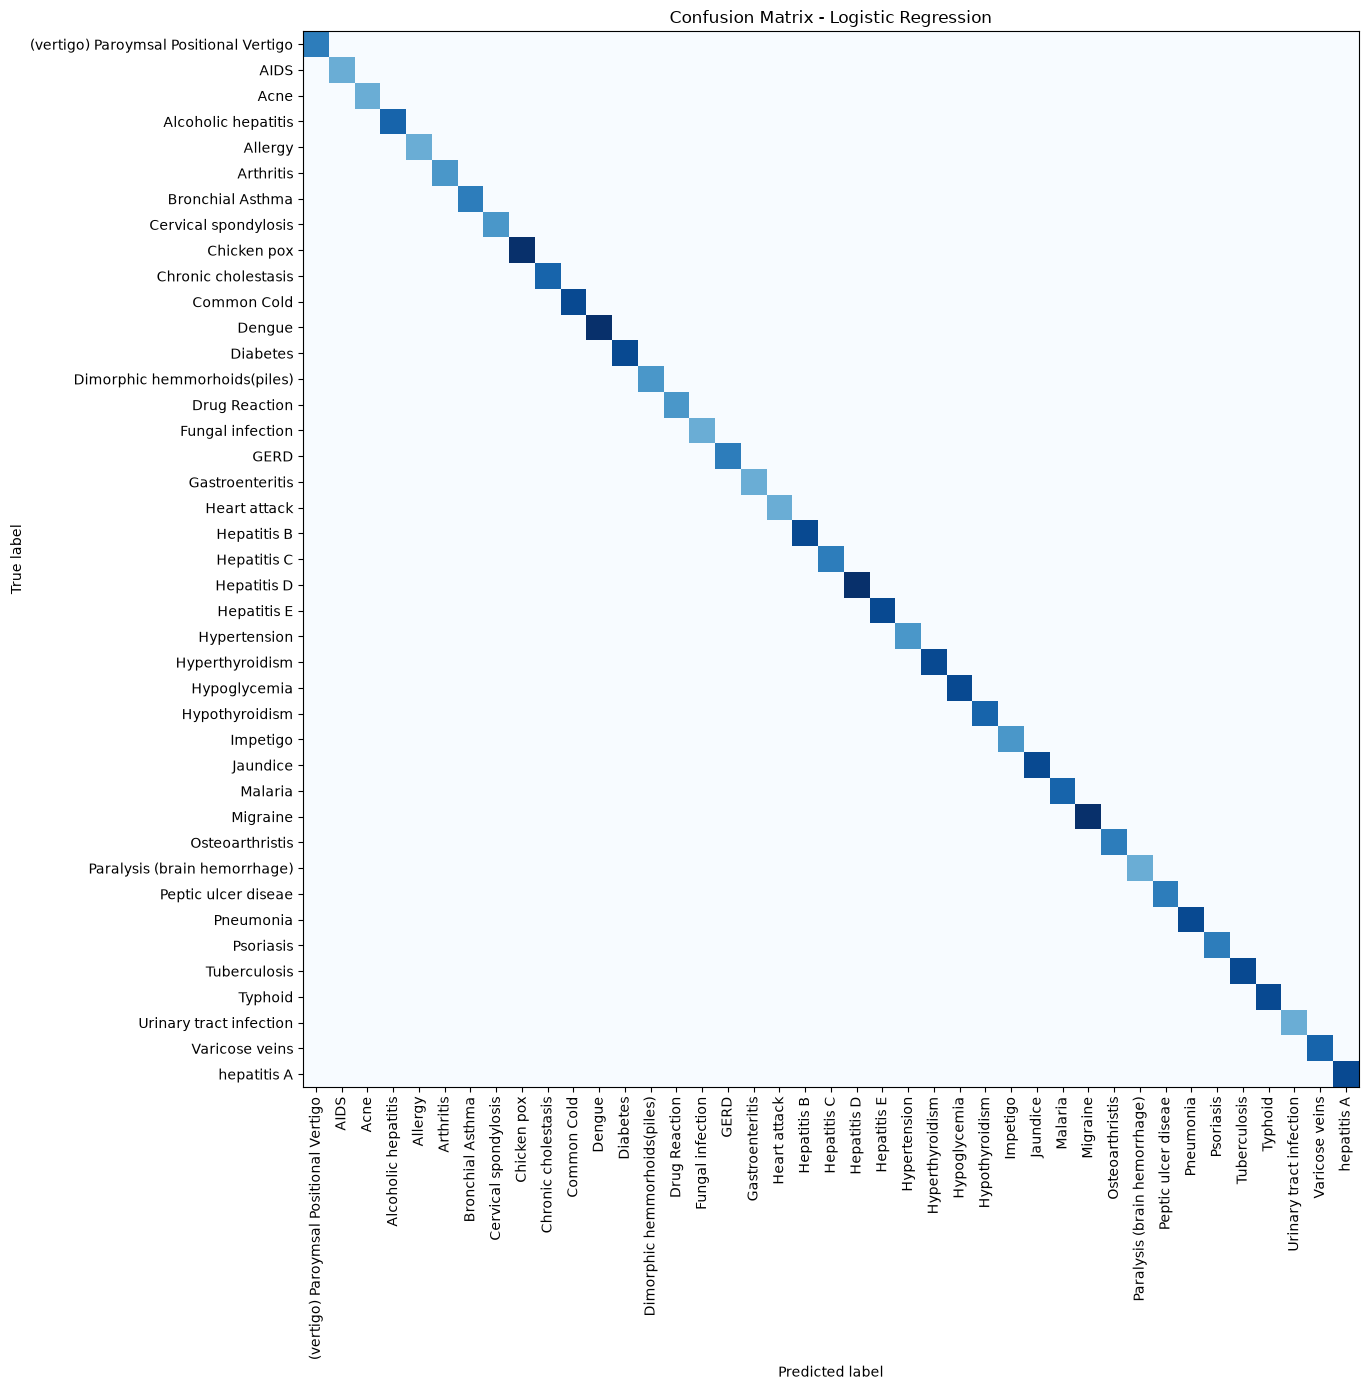

In [22]:
# Confusion matrix (rows = real disease, columns = predicted disease)
fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(y, cv_pred, ax=ax, xticks_rotation=90,
                                        include_values=False, colorbar=False, cmap='Blues')
plt.title('Confusion Matrix - ' + best_name)
plt.tight_layout()
plt.show()

In [23]:
# Precision, recall and F1 for every disease
print(classification_report(y, cv_pred, zero_division=0))

                                        precision    recall  f1-score   support

(vertigo) Paroymsal Positional Vertigo       1.00      1.00      1.00         7
                                  AIDS       1.00      1.00      1.00         5
                                  Acne       1.00      1.00      1.00         5
                   Alcoholic hepatitis       1.00      1.00      1.00         8
                               Allergy       1.00      1.00      1.00         5
                             Arthritis       1.00      1.00      1.00         6
                      Bronchial Asthma       1.00      1.00      1.00         7
                  Cervical spondylosis       1.00      1.00      1.00         6
                           Chicken pox       1.00      1.00      1.00        10
                   Chronic cholestasis       1.00      1.00      1.00         8
                           Common Cold       1.00      1.00      1.00         9
                                Dengue 

## 14. Final Prediction System
Now we use the three master-data files (description, precautions, severity) and build a function that takes symptoms and returns the disease.

In [24]:
# Retrain the final model on ALL unique data (evaluation is already finished)
final_model.fit(X, y)

# Load master data (these 3 files have no header row, so header=None)
desc = pd.read_csv('MasterData/symptom_Description.csv', header=None)
prec = pd.read_csv('MasterData/symptom_precaution.csv', header=None)
sev  = pd.read_csv('MasterData/Symptom_severity.csv', header=None)

# Make disease names clean (remove extra spaces) in the same way as before
desc[0] = desc[0].str.replace(r'\s+', ' ', regex=True).str.strip()
prec[0] = prec[0].str.replace(r'\s+', ' ', regex=True).str.strip()

# Dictionary 1: disease -> description
desc_dict = dict(zip(desc[0], desc[1]))
# One disease is spelled differently in this file, so we rename it to match
desc_dict['Dimorphic hemmorhoids(piles)'] = desc_dict.pop('Dimorphic hemorrhoids(piles)')

# Dictionary 2: disease -> list of precautions
prec_dict = {}
for i in range(len(prec)):
    disease = prec.loc[i, 0]
    steps = [p for p in prec.loc[i, 1:] if pd.notna(p)]     # ignore empty precautions
    prec_dict[disease] = steps

# Dictionary 3: symptom -> severity weight
sev[0] = sev[0].str.replace(' ', '')
severity_dict = dict(zip(sev[0], sev[1]))

# Check that every disease has a description and precautions
missing = [d for d in final_model.classes_ if d not in desc_dict or d not in prec_dict]
print('Diseases missing description/precautions:', missing if missing else 'none')

Diseases missing description/precautions: none


In [25]:
def predict_disease(symptom_list):
    # Start with all symptoms = 0
    patient = pd.DataFrame(0, index=[0], columns=feature_columns)

    # Switch ON the symptoms the user gave
    used = []
    for s in symptom_list:
        s = s.strip().lower().replace(' ', '_')
        if s in feature_columns:
            patient[s] = 1
            used.append(s)
        else:
            print('Unknown symptom ignored:', s)

    if len(used) == 0:
        print('No valid symptoms given.')
        return

    # Probability for each disease, then take the top 3
    probs = final_model.predict_proba(patient)[0]
    top3 = probs.argsort()[::-1][:3]

    print('Symptoms       :', ', '.join(used))
    print('Severity score :', sum(severity_dict[s] for s in used))
    print('-' * 55)
    for rank, idx in enumerate(top3, 1):
        print(rank, '.', final_model.classes_[idx], '-', round(probs[idx] * 100, 1), '%')

    best = final_model.classes_[top3[0]]
    print('-' * 55)
    print('About       :', desc_dict[best])
    print('Precautions :')
    for step in prec_dict[best]:
        print('   -', step)
    print('Note: this is a student project, not medical advice.')

predict_disease(['itching', 'skin_rash', 'nodal_skin_eruptions'])

Symptoms       : itching, skin_rash, nodal_skin_eruptions
Severity score : 8
-------------------------------------------------------
1 . Fungal infection - 53.1 %
2 . Drug Reaction - 7.8 %
3 . Acne - 3.7 %
-------------------------------------------------------
About       : In humans, fungal infections occur when an invading fungus takes over an area of the body and is too much for the immune system to handle. Fungi can live in the air, soil, water, and plants. There are also some fungi that live naturally in the human body. Like many microbes, there are helpful fungi and harmful fungi.
Precautions :
   - bath twice
   - use detol or neem in bathing water
   - keep infected area dry
   - use clean cloths
Note: this is a student project, not medical advice.


In [26]:
# Try another example (fewer, common symptoms -> the model should be less sure)
predict_disease(['headache', 'vomiting', 'nausea'])

Symptoms       : headache, vomiting, nausea
Severity score : 13
-------------------------------------------------------
1 . (vertigo) Paroymsal Positional Vertigo - 18.2 %
2 . Paralysis (brain hemorrhage) - 12.4 %
3 . Malaria - 6.7 %
-------------------------------------------------------
About       : Benign paroxysmal positional vertigo (BPPV) is one of the most common causes of vertigo — the sudden sensation that you're spinning or that the inside of your head is spinning. Benign paroxysmal positional vertigo causes brief episodes of mild to intense dizziness.
Precautions :
   - lie down
   - avoid sudden change in body
   - avoid abrupt head movment
   - relax
Note: this is a student project, not medical advice.


### Interactive demo (for the viva)
Select symptoms in the list (hold **Ctrl** to select more than one) and click the button.

In [27]:
import ipywidgets as widgets
from IPython.display import display, clear_output

symptom_box = widgets.SelectMultiple(
    options=[(s.replace('_', ' '), s) for s in feature_columns],
    rows=15, description='Symptoms', layout=widgets.Layout(width='450px'))
button = widgets.Button(description='Predict disease', button_style='primary')
output = widgets.Output()

def on_button_click(b):
    with output:
        clear_output()
        if len(symptom_box.value) == 0:
            print('Please select at least one symptom.')
        else:
            predict_disease(list(symptom_box.value))

button.on_click(on_button_click)
display(symptom_box, button, output)

SelectMultiple(description='Symptoms', layout=Layout(width='450px'), options=(('itching', 'itching'), ('skin r…

Button(button_style='primary', description='Predict disease', style=ButtonStyle())

Output()

## Conclusion
- The symptom data was inspected, cleaned, and converted into 131 binary features.
- The old 100% accuracy was caused by **data leakage**: `Training.csv` has only 304 unique rows in 4,920, and `Testing.csv` is fully contained in `Training.csv`.
- Duplicates were removed **before** splitting, and a check proves train and test share no rows.
- Six models were compared using accuracy, precision, recall, F1, 5-fold cross-validation and a robustness test.
- The Decision Tree overfits (about 100% train vs about 60-70% on new data). The other models generalise much better.
- A prediction system returns the top-3 diseases with confidence, a description, precautions and a severity score.

**Limitations:** the dataset is synthetic and clean (high scores reflect that), there are only 5-10 unique patterns per disease, and there is no age, gender or symptom duration. This is an educational project, not a medical tool.

**Future scope:** real hospital data, a web app (Streamlit), and explainable AI (SHAP).